# Evaluating Time-Aware Casual TCN

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import keras

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

I0000 00:00:1794477223.792762     793 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794477223.985259     793 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794477225.611727     793 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
model = keras.models.load_model(
    "sleep_tcn_120x18_elapsed_best.keras"
)

scaler = joblib.load("scaler_tcn_18.pkl")

features_18 = joblib.load("features_tcn_18.pkl")

print("Model input shape:", model.input_shape)
print("Number of features:", len(features_18))
print("Features:", features_18)

W0000 00:00:1794477296.817433     793 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1794477296.819537     793 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794477296.947610     793 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9217 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070, pci bus id: 0000:02:00.0, compute capability: 12.0a
E0000 00:00:1794477296.995722     793 cuda_executor.cc:1365] [0] Failed to allocate device memory of 9.00GiB (9664724992 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:45
external/xla/xla/

Model input shape: (None, 120, 18)
Number of features: 18
Features: ['hr_mean', 'hr_std', 'hr_min', 'hr_max', 'motion_mean', 'motion_std', 'motion_min', 'motion_max', 'hr_mean_roll5', 'motion_mean_roll5', 'hr_change', 'hr_mean_roll_std5', 'motion_mean_roll_std5', 'hr_mean_roll20', 'motion_mean_roll20', 'hr_mean_roll_std20', 'motion_mean_roll_std20', 'elapsed_hours']


In [4]:
test_df = pd.read_csv("test.csv")

print("Dataset shape:", test_df.shape)

print("\nColumns:")
print(test_df.columns.tolist())

print("\nParticipants:", test_df["person"].nunique())

print("Nights:", test_df.groupby(["person", "night"]).ngroups)

display(test_df.head())

Dataset shape: (39557, 14)

Columns:
['epoch', 'sleep_stage', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'hr_count', 'motion_mean', 'motion_std', 'motion_min', 'motion_max', 'person', 'night', 'stage_4']

Participants: 8
Nights: 47


,epoch,sleep_stage,hr_mean,hr_std,hr_min,hr_max,hr_count,motion_mean,motion_std,motion_min,motion_max,person,night,stage_4
0,0,0,73.200000,6.723095,67.0,81.0,5,1.017217,0.136386,0.600303,1.818675,Bidslab06,1,0
1,1,0,78.000000,2.516611,75.0,80.0,7,1.044633,0.218984,0.373403,2.122007,Bidslab06,1,0
2,2,0,78.000000,4.335897,74.0,86.0,6,1.011005,0.120664,0.523801,2.009796,Bidslab06,1,0
3,3,0,69.666667,2.160247,67.0,72.0,6,0.998027,0.004806,0.964379,1.038991,Bidslab06,1,0
4,4,0,66.500000,1.224745,65.0,68.0,6,1.004990,0.084384,0.512693,1.466803,Bidslab06,1,0


In [5]:
test_df = test_df.sort_values(
    ["person", "night", "epoch"]
).reset_index(drop=True)

# Check for duplicate epochs
assert not test_df.duplicated(
    ["person", "night", "epoch"]
).any()

# Identify the beginning of each continuous segment
new_segment = (
    test_df["person"].ne(test_df["person"].shift())
    | test_df["night"].ne(test_df["night"].shift())
    | test_df["epoch"].diff().ne(1)
)

test_df["segment_id"] = new_segment.cumsum()

test_df["position"] = test_df.groupby(
    "segment_id"
).cumcount()

print("Total epochs:", len(test_df))
print("Continuous segments:", test_df["segment_id"].nunique())
print("Eligible prediction epochs:", (test_df["position"] >= 19).sum())

display(test_df.head())

Total epochs: 39557
Continuous segments: 110
Eligible prediction epochs: 37802


,epoch,sleep_stage,hr_mean,hr_std,hr_min,hr_max,hr_count,motion_mean,motion_std,motion_min,motion_max,person,night,stage_4,segment_id,position
0,0,0,73.200000,6.723095,67.0,81.0,5,1.017217,0.136386,0.600303,1.818675,Bidslab06,1,0,1,0
1,1,0,78.000000,2.516611,75.0,80.0,7,1.044633,0.218984,0.373403,2.122007,Bidslab06,1,0,1,1
2,2,0,78.000000,4.335897,74.0,86.0,6,1.011005,0.120664,0.523801,2.009796,Bidslab06,1,0,1,2
3,3,0,69.666667,2.160247,67.0,72.0,6,0.998027,0.004806,0.964379,1.038991,Bidslab06,1,0,1,3
4,4,0,66.500000,1.224745,65.0,68.0,6,1.004990,0.084384,0.512693,1.466803,Bidslab06,1,0,1,4


In [6]:
group = test_df.groupby("segment_id")

for col in ["hr_mean", "motion_mean"]:
    test_df[f"{col}_roll5"] = group[col].transform(
        lambda x: x.rolling(5, min_periods=1).mean()
    )

    test_df[f"{col}_roll_std5"] = group[col].transform(
        lambda x: x.rolling(5, min_periods=2).std()
    ).fillna(0)

test_df["hr_change"] = group["hr_mean"].diff().fillna(0)

In [7]:
for col in ["hr_mean", "motion_mean"]:
    test_df[f"{col}_roll20"] = group[col].transform(
        lambda x: x.rolling(20, min_periods=1).mean()
    )

    test_df[f"{col}_roll_std20"] = group[col].transform(
        lambda x: x.rolling(20, min_periods=2).std()
    ).fillna(0)

In [8]:
night_start = test_df.groupby(
    ["person", "night"]
)["epoch"].transform("min")

test_df["elapsed_hours"] = (
    test_df["epoch"] - night_start
) / 120.0

In [9]:
print("Number of features:", len(features_18))

print("Missing values:")
print(test_df[features_18].isna().sum().sum())

print("\nFirst 5 rows:")
display(test_df[features_18].head())

Number of features: 18
Missing values:
0

First 5 rows:


,hr_mean,hr_std,hr_min,hr_max,motion_mean,motion_std,motion_min,motion_max,hr_mean_roll5,motion_mean_roll5,hr_change,hr_mean_roll_std5,motion_mean_roll_std5,hr_mean_roll20,motion_mean_roll20,hr_mean_roll_std20,motion_mean_roll_std20,elapsed_hours
0,73.200000,6.723095,67.0,81.0,1.017217,0.136386,0.600303,1.818675,73.200000,1.017217,0.000000,0.000000,0.000000,73.200000,1.017217,0.000000,0.000000,0.000000
1,78.000000,2.516611,75.0,80.0,1.044633,0.218984,0.373403,2.122007,75.600000,1.030925,4.800000,3.394113,0.019386,75.600000,1.030925,3.394113,0.019386,0.008333
2,78.000000,4.335897,74.0,86.0,1.011005,0.120664,0.523801,2.009796,76.400000,1.024285,0.000000,2.771281,0.017893,76.400000,1.024285,2.771281,0.017893,0.016667
3,69.666667,2.160247,67.0,72.0,0.998027,0.004806,0.964379,1.038991,74.716667,1.017720,-8.333333,4.056408,0.019642,74.716667,1.017720,4.056408,0.019642,0.025000
4,66.500000,1.224745,65.0,68.0,1.004990,0.084384,0.512693,1.466803,73.073333,1.015174,-3.166667,5.083656,0.017938,73.073333,1.015174,5.083656,0.017938,0.033333


In [10]:
# Apply the saved training scaler
X_test_scaled = scaler.transform(
    test_df[features_18]
)

# Convert to float32 for Keras
X_test_scaled = X_test_scaled.astype("float32")

# Verify the result
print("Scaled data shape:", X_test_scaled.shape)
print("Missing values:", np.isnan(X_test_scaled).sum())
print("Infinite values:", np.isinf(X_test_scaled).sum())

print("\nFirst scaled row:")
print(X_test_scaled[0])

Scaled data shape: (39557, 18)
Missing values: 0
Infinite values: 0

First scaled row:
[ 9.3022513e-01  2.9264786e+00  4.0707925e-01  1.4740049e+00
  3.2592556e+00  5.0495014e+00 -2.8692770e+00  2.1104112e+00
  9.8143262e-01  3.9992630e+00  7.8584056e-04 -8.8569605e-01
 -3.0499679e-01  1.0027140e+00  4.3044086e+00 -1.2977239e+00
 -5.2525717e-01 -1.6470395e+00]


In [11]:
sequence_length = 120

# Only predict from position 19 onward
end_indices = np.where(
    test_df["position"].to_numpy() >= 19
)[0]

# Prepare the input array
X_test = np.zeros(
    (len(end_indices), sequence_length, len(features_18)),
    dtype=np.float32
)

positions = test_df["position"].to_numpy()

for i, end_idx in enumerate(end_indices):

    # Available history, up to 120 epochs
    length = min(positions[end_idx] + 1, sequence_length)

    start_idx = end_idx - length + 1

    # Place history at the end (left-padding remains zero)
    X_test[i, -length:] = X_test_scaled[start_idx:end_idx + 1]

# Labels for the final epoch of each sequence
y_test = test_df["stage_4"].to_numpy()[end_indices]

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("Model input shape:", model.input_shape)

print("Missing values:", np.isnan(X_test).sum())

X_test shape: (37802, 120, 18)
y_test shape: (37802,)
Model input shape: (None, 120, 18)
Missing values: 0


In [12]:
# Check the input dimensions
assert X_test.shape == (37802, 120, 18)
assert y_test.shape == (37802,)

# Check that there are no missing values
assert np.isfinite(X_test).all()

# Check that no prohibited features were used
assert "hr_count" not in features_18

# Check that every window ends at the correct epoch
assert np.allclose(
    X_test[:, -1, :],
    X_test_scaled[end_indices]
)

# Check the first window's left-padding
assert np.all(X_test[0, :100, :] == 0)

print("All sequence checks passed!")
print("Total test sequences:", len(X_test))
print("Input shape:", X_test.shape)

All sequence checks passed!
Total test sequences: 37802
Input shape: (37802, 120, 18)


In [13]:
# Predict sleep stages
y_prob = model.predict(
    X_test,
    batch_size=256,
    verbose=1
)

# Convert probabilities to predicted classes
y_pred = np.argmax(y_prob, axis=1)

# Calculate metrics
test_accuracy = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Test Accuracy: {test_accuracy:.2%}")
print(f"Test Macro F1: {test_f1:.4f}")
print(f"Evaluated epochs: {len(y_test)}")

I0000 00:00:1794478250.548794     960 service.cc:154] XLA service 0x7e6e1c5125e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794478250.548849     960 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 5070, Compute Capability 12.0a (Driver: 13.3.0[610.88.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1794478250.579562     960 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794478250.915390     960 cuda_dnn.cc:442] Loaded cuDNN version 92700


 86/148 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

I0000 00:00:1794478252.301066     960 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
Test Accuracy: 66.69%
Test Macro F1: 0.6689
Evaluated epochs: 37802


In [14]:
stage_names = ["Wake", "Light", "Deep", "REM"]

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=stage_names,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

        Wake     0.6799    0.6308    0.6544      3613
       Light     0.6715    0.6428    0.6569     16712
        Deep     0.6951    0.7168    0.7058      7458
         REM     0.6360    0.6831    0.6587     10019

    accuracy                         0.6669     37802
   macro avg     0.6706    0.6684    0.6689     37802
weighted avg     0.6676    0.6669    0.6668     37802



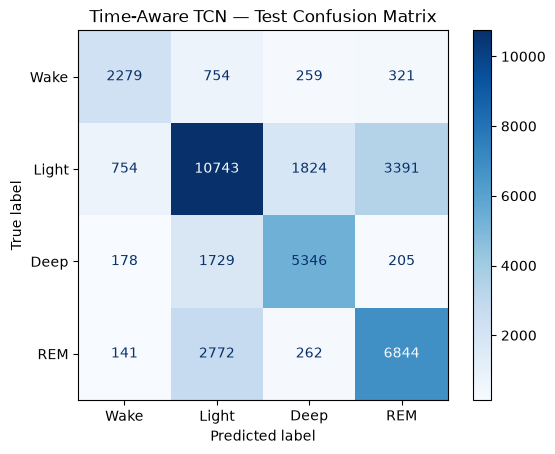

In [15]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=stage_names
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Time-Aware TCN — Test Confusion Matrix")
plt.show()

In [16]:
results_df = pd.DataFrame({
    "person": test_df.iloc[end_indices]["person"].values,
    "actual": y_test,
    "predicted": y_pred
})

participant_results = []

for person, group in results_df.groupby("person"):

    accuracy = accuracy_score(
        group["actual"],
        group["predicted"]
    )

    macro_f1 = f1_score(
        group["actual"],
        group["predicted"],
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    )

    participant_results.append({
        "Person": person,
        "Epochs": len(group),
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

participant_df = pd.DataFrame(participant_results)

display(
    participant_df.sort_values("Accuracy").round(4)
)

,Person,Epochs,Accuracy,Macro F1
4,Bidslab41,5857,0.6143,0.6050
1,Bidslab07,5950,0.6331,0.6301
2,Bidslab39,3178,0.6652,0.6574
3,Bidslab40,6059,0.6704,0.6776
0,Bidslab06,3241,0.6791,0.6796
6,Bidslab56,3718,0.6832,0.6815
5,Bidslab52,4640,0.6892,0.6810
7,Bidslab60,5159,0.7234,0.6525


In [17]:
results_df.to_csv(
    "tcn_test_predictions.csv",
    index=False
)

participant_df.to_csv(
    "tcn_test_participant_results.csv",
    index=False
)

print("Final test results saved successfully!")

Final test results saved successfully!
